# Crypto Lab 10 — Quantum and Post-Quantum Cryptography

## Today’s Big Question

**How does quantum computing change the security assumptions behind modern cryptography, and what kinds of cryptography can replace the systems it threatens?**

This notebook uses **classical simulations and toy examples**. It does not run on a quantum computer and it does not implement production post-quantum cryptography.

## Why This Matters

Cryptography is built on assumptions about what attackers can compute. RSA assumes large integer factorization is infeasible. Diffie–Hellman and elliptic-curve systems assume discrete logarithms are infeasible. Quantum algorithms change those assumptions.

The engineering lesson is broader than quantum computing:

> **A cryptosystem is secure only while its assumptions, parameters, implementation, and operating environment remain sound.**

We will model the chapter’s main ideas without requiring a quantum-computing library.

In [1]:
from __future__ import annotations

import math
import secrets
from hashlib import sha256

import matplotlib.pyplot as plt
import numpy as np

print("Quantum / post-quantum modeling lab ready.")

Quantum / post-quantum modeling lab ready.


## Part 1 — A Qubit Is Not Just a Random Bit

A classical bit is 0 or 1. A qubit is described by two **amplitudes**, usually written α and β:

**|ψ⟩ = α|0⟩ + β|1⟩**

When measured, the probability of observing 0 is |α|² and the probability of observing 1 is |β|². These probabilities must sum to 1.

In [2]:
def measurement_probabilities(alpha: complex, beta: complex) -> tuple[float, float]:
    p0 = abs(alpha) ** 2
    p1 = abs(beta) ** 2
    if not np.isclose(p0 + p1, 1.0):
        raise ValueError("Amplitudes must be normalized so probabilities sum to 1.")
    return p0, p1

alpha = 1 / math.sqrt(2)
beta = 1 / math.sqrt(2)
p0, p1 = measurement_probabilities(alpha, beta)
print(f"P(0) = {p0:.3f}")
print(f"P(1) = {p1:.3f}")

P(0) = 0.500
P(1) = 0.500


### Exercise 1 — Same Probabilities, Different State

Consider these two qubit states:

- State A: α = 1/√2, β = 1/√2
- State B: α = i/√2, β = -1/√2

1. Compute the measurement probabilities for State B.
2. Are the two states mathematically identical just because they have the same measurement probabilities?
3. Why does this distinction matter when quantum gates later transform amplitudes?

**Your answer:**
1. 50-50, equal change for 1 or 0
2. No amplitudes are the same but they have different values
3. The larger the amplitude the more the small differences will expand.

In [3]:
alpha_b = 1j / math.sqrt(2)
beta_b = -1 / math.sqrt(2)
print(measurement_probabilities(alpha_b, beta_b))

(0.4999999999999999, 0.4999999999999999)


## Part 2 — Quantum Gates as Transformations

The chapter describes a quantum gate as a reversible transformation of amplitudes. In a classical simulation we can represent a one-qubit gate as a 2×2 matrix.

The **Hadamard gate** is especially useful because it moves between deterministic and equal-superposition states.

In [4]:
H = (1 / math.sqrt(2)) * np.array([
    [1,  1],
    [1, -1],
], dtype=complex)

ket0 = np.array([1, 0], dtype=complex)
psi = H @ ket0
back_to_zero = H @ psi

print("H|0> =", np.round(psi, 4))
print("H(H|0>) =", np.round(back_to_zero, 4))
print("Measurement probabilities after first H:", np.abs(psi) ** 2)

H|0> = [0.7071+0.j 0.7071+0.j]
H(H|0>) = [1.+0.j 0.+0.j]
Measurement probabilities after first H: [0.5 0.5]


### Exercise 2 — Reversibility

1. What state do you get after applying H to |0⟩?
2. What happens when you apply H a second time?
3. How does this illustrate the chapter’s point that valid quantum gates are reversible?

**Your answer:**
1. It flips it to a classical bit(only 1 or 0).
2. Since its an inverse it will go back to a superposition
3. Because I can switch from classical to quantum bits using this gate.

## Part 3 — Quantum Speedup Is About Complexity

Quantum computers are not “infinitely fast computers.” Their advantage comes from algorithms that require fewer operations for certain problems.

For an unstructured search among N possibilities:

- classical search scales on the order of **N**,
- Grover-style quantum search scales on the order of **√N**.

Let’s compare the growth rates.

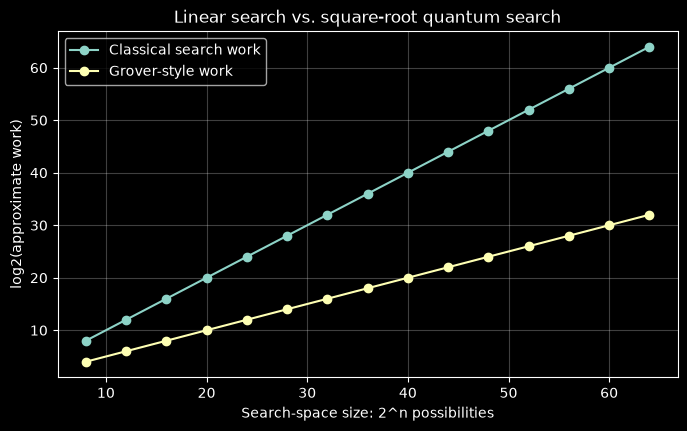

In [5]:
exponents = np.arange(8, 65, 4)
N = 2.0 ** exponents
classical = N
quantum = np.sqrt(N)

plt.figure(figsize=(8, 4.5))
plt.plot(exponents, np.log2(classical), marker="o", label="Classical search work")
plt.plot(exponents, np.log2(quantum), marker="o", label="Grover-style work")
plt.xlabel("Search-space size: 2^n possibilities")
plt.ylabel("log2(approximate work)")
plt.title("Linear search vs. square-root quantum search")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Exercise 3 — Security Bits Under Grover

Complete the table conceptually.

| Classical key size | Classical brute-force work | Idealized Grover-style work | Approx. post-quantum security |
|---|---:|----------------------------:|------------------------------:|
| 128 bits | 2^128 |                        2^64 |                       64 bits |
| 192 bits | 2^192 |                        2^96 |                       96 bits |
| 256 bits | 2^256 |                       2^128 |                      128 bits |

Why does this motivate larger symmetric keys rather than abandoning symmetric cryptography entirely?

**Your answer:**
- With a larger key it can still have secrecy.

In [6]:
for bits in (128, 192, 256):
    print(f"{bits}-bit key -> about 2^{bits//2} Grover-style search work")

128-bit key -> about 2^64 Grover-style search work
192-bit key -> about 2^96 Grover-style search work
256-bit key -> about 2^128 Grover-style search work


## Part 4 — Shor and the Public-Key Problem

The chapter’s central warning is that Shor’s algorithm changes the difficulty of:

- integer factorization,
- the discrete logarithm problem,
- and the elliptic-curve discrete logarithm problem.

Those assumptions support RSA, classical Diffie–Hellman, and elliptic-curve cryptography.

### Exercise 4 — Threat Mapping

Fill in the table.

| Cryptographic system | Main hardness assumption | Shor threatens it? | What would need to change?             |
|---|--------------------------|--------------------|----------------------------------------|
| RSA | factoruing               | Yes                | Move to diffrent public key encryption |
| Diffie–Hellman | exponents                | yes                | Move to diffrent secret encryption     |
| ECDH / ECDSA | logeretnmic problem      | Yes                | Move to diffrent digital signature     |
| AES | search key               | No                 | Larger keys                            |
| SHA-256 | One way, no reversing    | No                 | Large hashes                           |

Then answer: **Why is the quantum threat qualitatively different for public-key systems than for AES?**
- Public key is broken but AES isn't as broken

## Part 5 — Why “Harvest Now, Decrypt Later” Matters

An attacker does not need a quantum computer today to create future risk. They may capture ciphertext today and keep it until they have better cryptanalytic capabilities.

This matters most when the protected information must remain confidential for a long time.

In [7]:
examples = {
    "temporary login token": 0.01,
    "quarterly business plan": 1,
    "student academic record": 10,
    "government personnel file": 30,
}

for item, years in examples.items():
    print(f"{item:28s} secrecy horizon ≈ {years} years")

temporary login token        secrecy horizon ≈ 0.01 years
quarterly business plan      secrecy horizon ≈ 1 years
student academic record      secrecy horizon ≈ 10 years
government personnel file    secrecy horizon ≈ 30 years


### Exercise 5 — Prioritizing Migration

Rank the four example data types above from **lowest** to **highest** urgency for post-quantum confidentiality planning. Explain your ranking.
1. government personnel file
2. student academic record
3. quarterly business plan
4. temporary login token
What other factor besides the length of the secrecy period should an organization consider?

**Your answer:**
The token expires superfast so that is least, Business plan could be used to manipulate the market or hurt a large company, Student info can include PI like bank info or SSN, and most important is gov files, they may have valuable information or may be targets if they are known.

## Part 6 — Toy Code-Based Cryptography Idea

Code-based cryptography builds on error-correcting codes. We will not implement McEliece, but we can model the core intuition: add redundancy so a receiver with the right structure can recover from limited errors.

This repetition code encodes each bit three times and decodes by majority vote.

In [8]:
def repetition_encode(bits: str) -> str:
    if any(b not in "01" for b in bits):
        raise ValueError("bits must contain only 0 and 1")
    return "".join(bit * 3 for bit in bits)


def repetition_decode(encoded: str) -> str:
    if len(encoded) % 3:
        raise ValueError("encoded length must be divisible by 3")
    decoded = []
    for i in range(0, len(encoded), 3):
        chunk = encoded[i:i+3]
        decoded.append("1" if chunk.count("1") >= 2 else "0")
    return "".join(decoded)

message = "0101"
encoded = repetition_encode(message)
corrupted = list(encoded)
corrupted[1] = "1" if corrupted[1] == "0" else "0"
corrupted = "".join(corrupted)

print("message:   ", message)
print("encoded:   ", encoded)
print("corrupted: ", corrupted)
print("decoded:   ", repetition_decode(corrupted))

message:    0101
encoded:    000111000111
corrupted:  010111000111
decoded:    0101


### Exercise 6 — Error Correction vs. Cryptographic Hardness

1. How many bit errors per 3-bit chunk can this repetition code reliably correct?
2. Why is this toy code **not** a cryptosystem?
3. In a real code-based public-key system, what additional property must make decoding hard for an attacker but manageable for the legitimate recipient?

**Your answer:**
1. one bit error
2. It isn't very reliable and isnt actualy hiding anything, if you know how to decode it then it is easy.
3. The recipient has a key to undo it. this makes it easy to decode one way but difficult the other way, like a trap door.

## Part 7 — A Tiny Learning-With-Errors Model

Lattice-based cryptography often uses problems related to **learning with errors (LWE)**. The simplified relation is:

**b = A·s + e (mod q)**

where `s` is secret and `e` is a small noise vector. Without the noise, solving for `s` is ordinary modular linear algebra. The noise is what changes the problem.

The numbers below are far too small for security; they exist only to show the structure.

In [9]:
q = 17
A = np.array([
    [2, 5],
    [7, 3],
    [4, 9],
    [6, 1],
], dtype=int)
s = np.array([4, 11], dtype=int)
e = np.array([1, 0, -1, 1], dtype=int)
b = (A @ s + e) % q

print("A =")
print(A)
print("b =", b)
print("q =", q)

A =
[[2 5]
 [7 3]
 [4 9]
 [6 1]]
b = [13 10 12  2]
q = 17


### Exercise 7 — Why Add Noise?

Compare these two problems:

- `b = A·s mod q`
- `b = A·s + e mod q`

Why does adding the small unknown vector `e` make recovery of `s` less straightforward? Why would simply making `e` enormous not automatically make a good cryptosystem?

**Your answer:**
- It is similar to salting a hash, it makes it less algebraic and more complex for quantum computers, but easier for the recipient since it's a known value.

## Part 8 — A Simplified Hash-Chain One-Time Signature

Hash-based signatures depend on the one-way behavior of hash functions rather than factoring or discrete logarithms.

The following toy demonstrates a one-way hash chain. It is deliberately incomplete and must **not** be used as a real signature scheme.

In [10]:
def H(data: bytes) -> bytes:
    return sha256(data).digest()


def hash_n(data: bytes, n: int) -> bytes:
    for _ in range(n):
        data = H(data)
    return data

w = 16
private_seed = secrets.token_bytes(32)
public_value = hash_n(private_seed, w)
message_value = 6
signature_value = hash_n(private_seed, message_value)
verified_value = hash_n(signature_value, w - message_value)

print("Toy signature verifies:", verified_value == public_value)

Toy signature verifies: True


### Exercise 8 — Why One-Time Means One-Time

Suppose an attacker sees a hash-chain signature corresponding to a small message value. Why can the attacker continue hashing that value forward? Why can’t the attacker efficiently move backward in the chain?

How does revealing multiple points on a one-way chain create additional forgery opportunities?

**Your answer:** they have the hash so they can continue hashing it, while the last hash is a one way function so unless you known the unknown original value you will not find it. if they have multiple hashes then it could reveal the secret.

## Part 9 — Migration Is a System Problem

A post-quantum migration is not simply “replace RSA with a new algorithm.” Systems have to consider:

- certificates and trust infrastructure,
- protocol negotiation,
- key and signature sizes,
- software/library support,
- hardware constraints,
- interoperability,
- long-lived encrypted data,
- rollback and downgrade risks,
- and implementation maturity.

During transition, systems may use **hybrid** designs that combine a classical mechanism with a post-quantum mechanism.

### Design Scenario

You operate a service that currently uses:

- ECDH for session key establishment,
- ECDSA certificates,
- AES-256-GCM for data protection,
- SHA-256 in several protocol components.

For each component, mark it as:

- **replace/augment first**, or
- **likely retain with appropriate parameters**.

Explain your reasoning. Your answer should distinguish the effect of Shor’s algorithm from the effect of Grover’s algorithm.

**Your answer:**
- Change ECDH and ECDSA soon, they are insecure and will be the first to fail
- Augment AES by making longer keys for long term storage
- SHA-256 is safe and cane remain with longer hashes

## Part 10 — Implementation Still Wins or Loses

Post-quantum mathematics does not eliminate ordinary software-security problems. A theoretically quantum-resistant algorithm can still fail because of:

- incorrect parameter validation,
- memory-safety bugs,
- bad randomness,
- side-channel leakage,
- protocol downgrade behavior,
- or incorrect key handling.

That connects directly to one of this course’s recurring themes: **security is a system property.**

## Final Reflection

Answer each in 2–4 sentences.

1. Why does Shor’s algorithm create a more severe problem for RSA/ECC than Grover’s algorithm creates for AES?
- RSA and Elliptic curve is broken by it. They will be taken from exponential to polynomial time while AES is only cut in half.
2. Why is “use post-quantum cryptography” an incomplete migration strategy?
- It is untested, not everything can run it, computationally expensive, Updating the worlds encryption standards will take time and is a slow process.
3. Which post-quantum family from the chapter seems most practical to you, and what tradeoff does it introduce?
- Lattice based it is faster than most and has quite a bit of mathematical proof behind it especially for its best case breaking complexity. But it is relatively new and has plenty of room to break.
4. Explain “harvest now, decrypt later” to a system administrator who has never studied quantum computing.
- Attackers will listen into sensitive encrypted communication that is secure now. Later in a few decades the attacker can use a quantum computer and decompile them all.
5. Finish the sentence: **Quantum-safe cryptography does not mean…**
- Secure, it can still have bugs especially with how new it is and how untested it is, and that it will be secure forever, an attacker in the future may have a quantum computer with way more power than we can even prodict now!

## Submission Checklist

- [ ] Completed Exercises 1–8
- [ ] Ran all code cells
- [ ] Completed the migration design scenario
- [ ] Completed the final reflection
- [ ] Can distinguish Shor’s impact from Grover’s impact
- [ ] Can explain why this notebook models concepts rather than implementing production PQC